# 02 · Análisis exploratorio (EDA)

Exploración del dataset limpio: distribución de las métricas LRFMC, transformaciones, relaciones
entre variables y perfil de los socios. Los gráficos son interactivos en JupyterLab, VS Code o
nbviewer; en GitHub se ven como imagen estática.

- **Entrada:** `data/interim/flight_clean.parquet` (`uv run poe clean`).
- Versión web con los mismos gráficos: página **EDA** del sitio Quarto.

| Métrica | Definición | Pregunta de negocio |
|---|---|---|
| **L** | meses entre `FFP_DATE` y `LOAD_TIME` | ¿Hace cuánto que es cliente? |
| **R** | `LAST_TO_END` / 30 | ¿Hace cuánto que no vuela? |
| **F** | `FLIGHT_COUNT` | ¿Con qué frecuencia vuela? |
| **M** | `SEG_KM_SUM` | ¿Cuánto vuela? |
| **C** | `avg_discount` | ¿Paga tarifa completa o compra en oferta? |

In [1]:
import pandas as pd

from segmentacion.config import get_config
from segmentacion.viz import eda_charts as ec
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
config = get_config()

df = pd.read_parquet(config.clean_file)
lrfmc = ec.lrfmc_preview(df)
summary = ec.eda_summary(df)
print(f"{len(df):,} socios")

62,044 socios


## 1. Estadísticos de las métricas LRFMC

In [2]:
stats_table = lrfmc.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
stats_table["asimetría"] = lrfmc.skew()
stats_table

,count,mean,std,min,25%,50%,75%,99%,max,asimetría
L,"62,044.00",48.91,27.86,11.99,24.15,41.99,71.69,109.27,112.92,0.52
R,"62,044.00",5.75,6.05,0.03,0.97,3.50,8.67,22.83,24.37,1.21
F,"62,044.00",11.97,14.11,2.00,3.00,7.00,15.00,70.00,213.00,3.20
M,"62,044.00","17,321.69","21,052.73",368.00,"4,874.00","10,200.00","21,522.50","101,367.37","580,717.00",3.87
C,"62,044.00",0.72,0.18,0.14,0.61,0.71,0.81,1.41,1.50,0.98


## 2. Distribución

Usa el selector de variable y el de escala (lineal / logarítmica) bajo el gráfico.

alt.Chart(...)
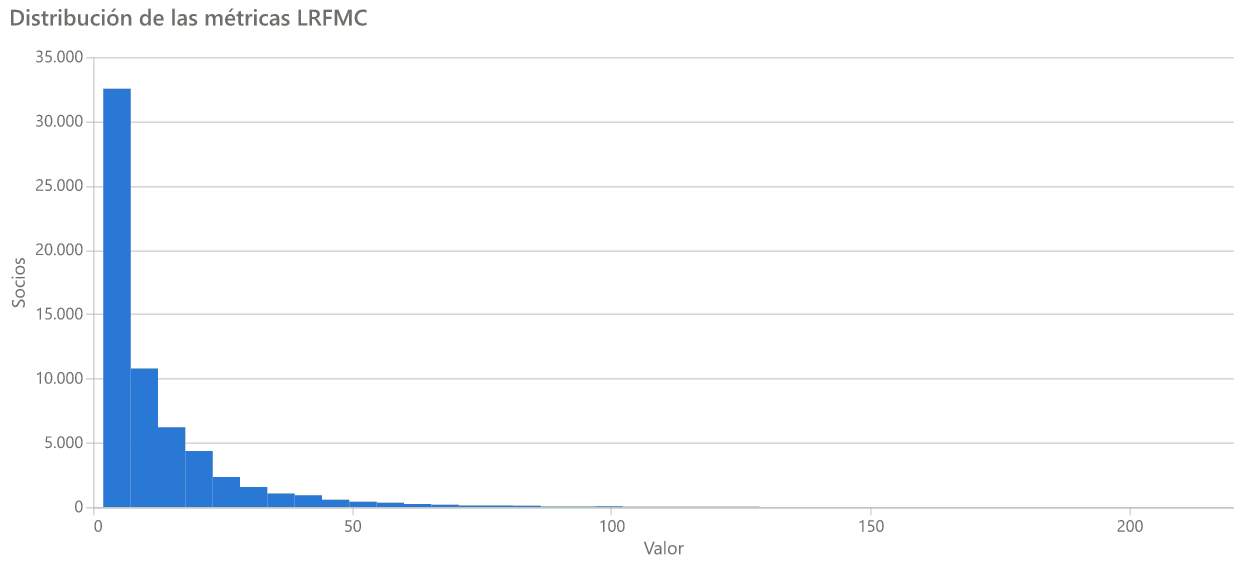

In [3]:
ec.distribution_chart(df)

**Qué vemos.** F y M tienen una cola larga a la derecha (asimetría > 3): el socio mediano hizo
7 vuelos y 10.200 km en dos años, pero hay socios con más de 200 vuelos. R se concentra en los
primeros meses y C se agrupa en torno a 0,71.

**Qué implica.** K-Means usa distancias euclídeas: sin transformar, unos pocos viajeros
intensivos dominarían los centroides.

## 3. Efecto de las transformaciones

In [4]:
pd.DataFrame(
    {
        "sin transformar": summary["skew"],
        "log1p": summary["skew_log1p"],
        "Yeo-Johnson": summary["skew_yeojohnson"],
    }
).round(2)

,sin transformar,log1p,Yeo-Johnson
L,0.52,-0.17,-0.04
R,1.21,0.09,0.02
F,3.20,0.54,0.09
M,3.87,0.10,0.01
C,0.98,0.42,-0.04


alt.FacetChart(...)
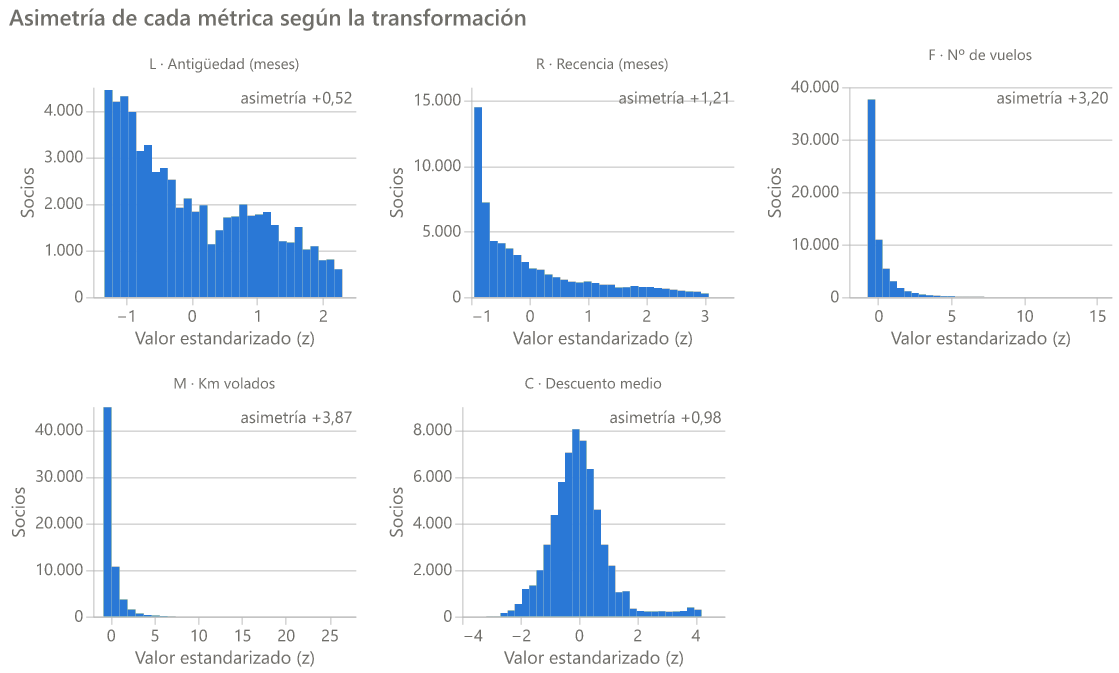

In [5]:
ec.skewness_chart(df)

**Qué vemos.** `log1p` corrige M y R pero deja F (0,54) y C (0,42) asimétricas; Yeo-Johnson
deja las cinco métricas con |asimetría| < 0,1.

**Qué implica.** Yeo-Johnson es la candidata para la fase de transformación y escalado.

## 4. Correlación (Spearman)

Spearman trabaja con rangos, así que no le afecta la asimetría.

alt.LayerChart(...)
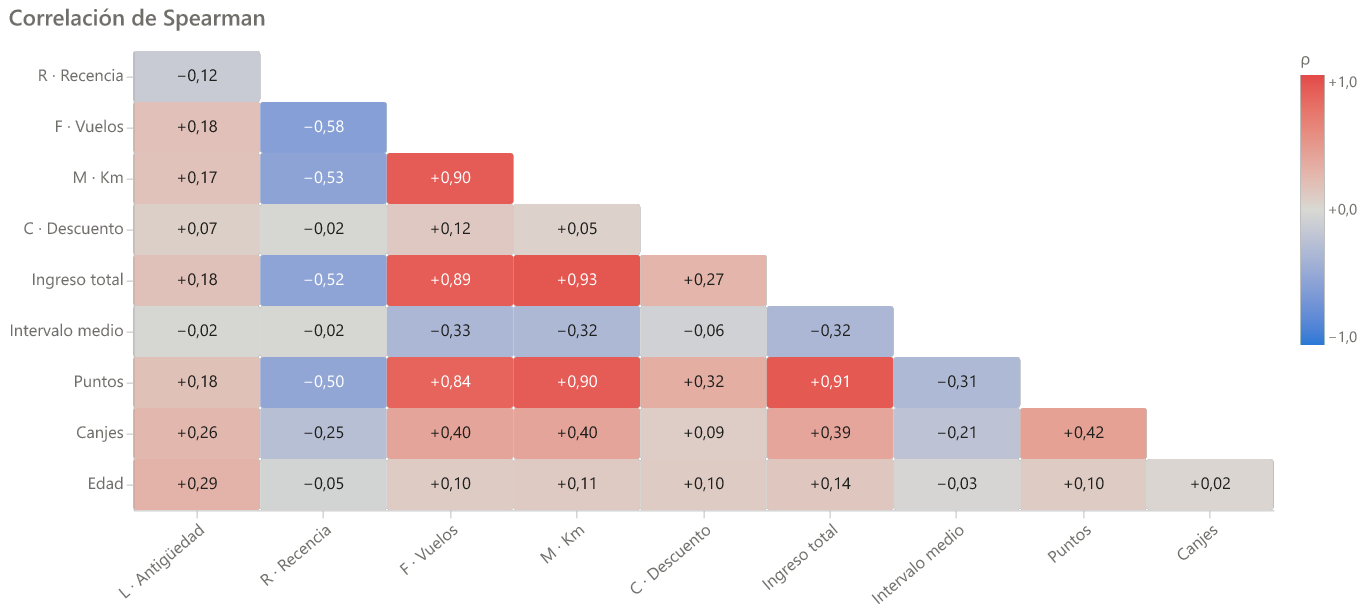

In [6]:
ec.correlation_heatmap(df)

**Qué vemos.** F y M están muy correlacionadas (ρ ≈ 0,90) y ambas siguen al ingreso y a los
puntos. R va en sentido contrario a F (ρ ≈ −0,58). C es casi independiente del resto.

**Qué implica.** F y M aportan información parecida y pesan casi el doble en la distancia; C
aporta una dimensión propia: la sensibilidad al precio.

## 5. ¿Qué mide `avg_discount`?

Si C es el precio pagado sobre la tarifa completa, el ingreso por km debería crecer con C.

In [7]:
revenue_per_km = (df["SUM_YR_1"] + df["SUM_YR_2"]) / df["SEG_KM_SUM"]
buckets = pd.cut(df["avg_discount"], [0, 0.4, 0.6, 0.8, 1.0, 1.5])
print(f"Spearman(C, ingreso por km) = {summary['spearman_c_revenue_km']:.2f}")
pd.DataFrame(
    {
        "socios": buckets.value_counts().sort_index(),
        "ingreso por km (mediana)": revenue_per_km.groupby(buckets, observed=True).median(),
    }
)

Spearman(C, ingreso por km) = 0.72


,socios,ingreso por km (mediana)
avg_discount,,
"(0.0, 0.4]",1990,0.33
"(0.4, 0.6]",12034,0.47
"(0.6, 0.8]",31418,0.62
"(0.8, 1.0]",13671,0.80
"(1.0, 1.5]",2931,1.13


El ingreso por km sigue de cerca al valor de C: **1,0 = tarifa completa**, valores < 1 son
tarifas con descuento y > 1 (4,7 % de los socios) corresponden a cabinas premium.

## 6. Vuelos, km y descuento

Arrastra sobre el scatter para seleccionar socios: el histograma de la derecha muestra su
descuento medio.

alt.HConcatChart(...)
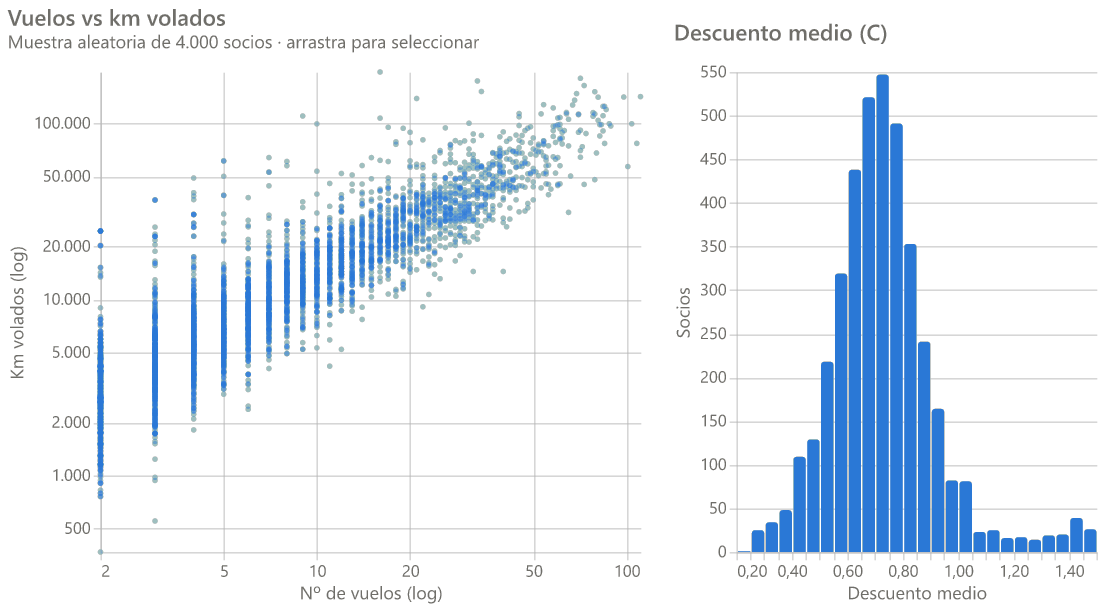

In [8]:
ec.frequency_km_scatter(df, seed=config.random_state)

**Qué implica.** Volumen (F, M) y precio (C) son ejes distintos: hay viajeros frecuentes que
cazan ofertas y viajeros ocasionales que pagan tarifa completa.

## 7. Métricas por nivel del programa

In [9]:
tiers = (
    df.assign(ingreso=df["SUM_YR_1"] + df["SUM_YR_2"])
    .groupby("FFP_TIER")
    .agg(
        socios=("MEMBER_NO", "size"),
        vuelos_mediana=("FLIGHT_COUNT", "median"),
        km_mediana=("SEG_KM_SUM", "median"),
        descuento_mediana=("avg_discount", "median"),
        recencia_dias_mediana=("LAST_TO_END", "median"),
        ingreso_total=("ingreso", "sum"),
    )
)
tiers["pct_socios"] = tiers["socios"] / tiers["socios"].sum()
tiers["pct_ingreso"] = tiers["ingreso_total"] / tiers["ingreso_total"].sum()
tiers

,socios,vuelos_mediana,km_mediana,descuento_mediana,recencia_dias_mediana,ingreso_total,pct_socios,pct_ingreso
FFP_TIER,,,,,,,,
4,57124,6.00,"9,272.50",0.70,118.00,"483,387,478.29",0.92,0.70
5,3409,37.00,"46,539.00",0.77,12.00,"122,763,925.00",0.05,0.18
6,1511,39.00,"51,925.00",0.86,13.00,"80,435,247.00",0.02,0.12


alt.FacetChart(...)
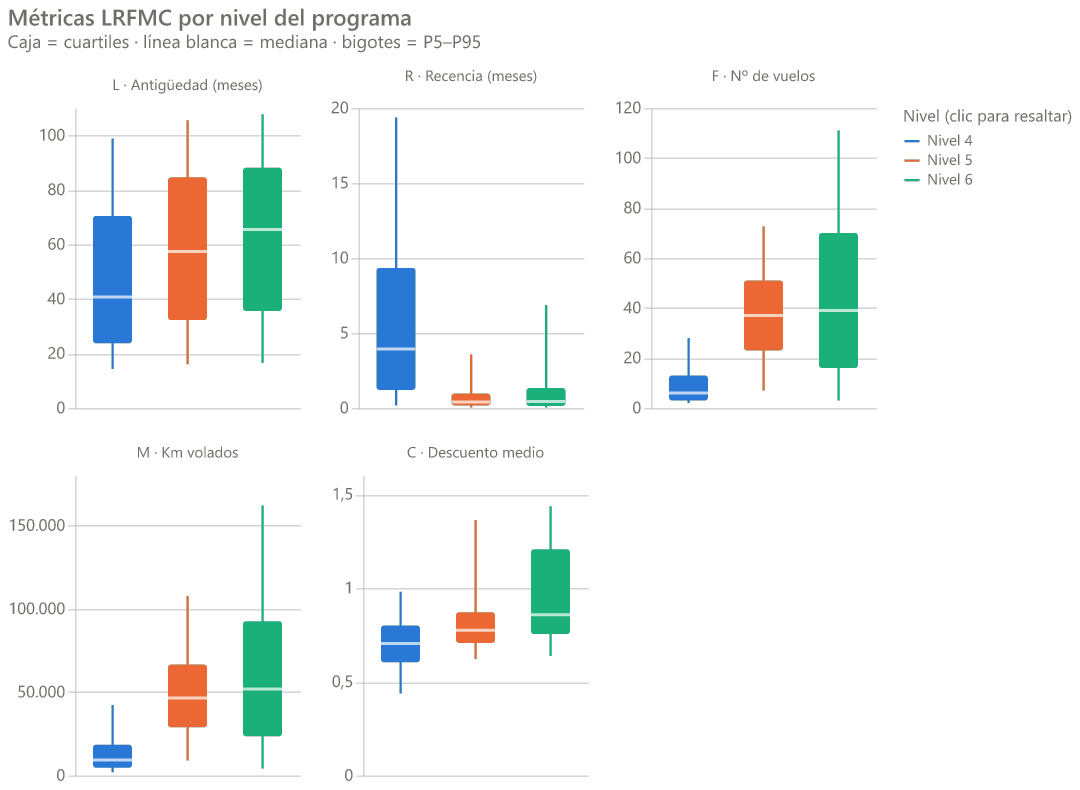

In [10]:
ec.tier_boxplot_chart(df)

**Qué vemos.** Los niveles 5 y 6 son el 7,9 % de los socios pero generan el 29,6 % del
ingreso; vuelan unas seis veces más que el nivel 4 y pagan tarifas más cercanas a la completa.

**Qué implica.** El nivel del programa solo separa a la élite; el nivel 4 (92 % de los socios)
agrupa perfiles muy distintos. Ahí está el valor de la segmentación, y el nivel servirá como
validación externa.

## 8. Edad y género

alt.Chart(...)
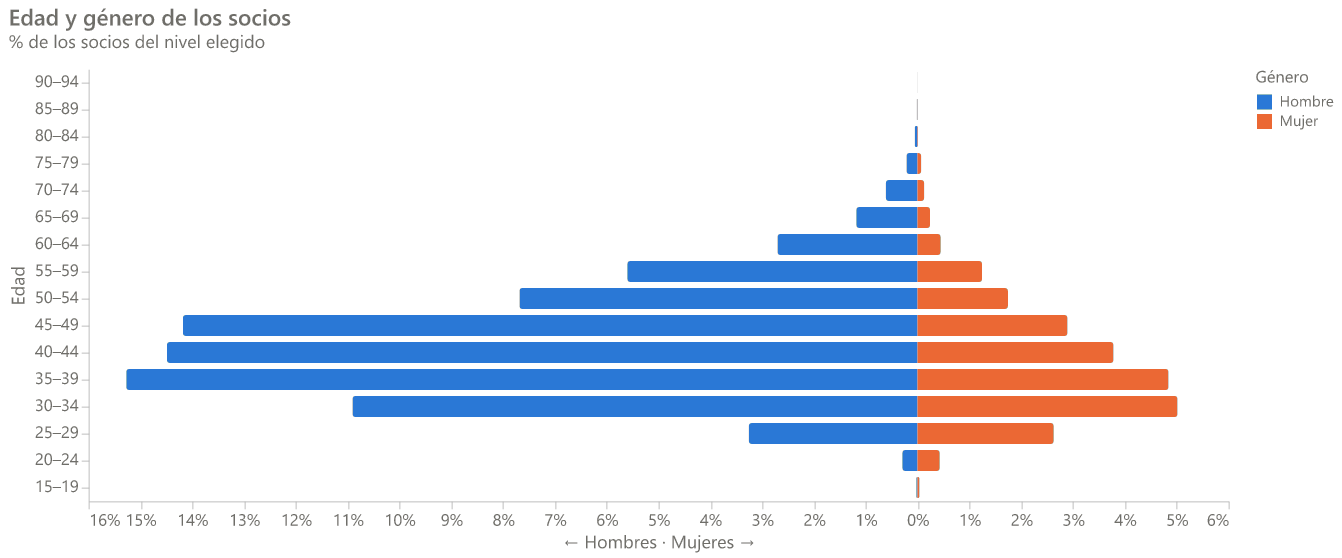

In [11]:
ec.age_gender_chart(df)

El 76,5 % de los socios son hombres (86,9 % en los niveles 5–6) y la edad mediana es 41 años:
perfil típico del viajero de negocios. Edad y género no entran al clustering, pero ayudan a
describir los segmentos.

## 9. Ubicación

alt.LayerChart(...)
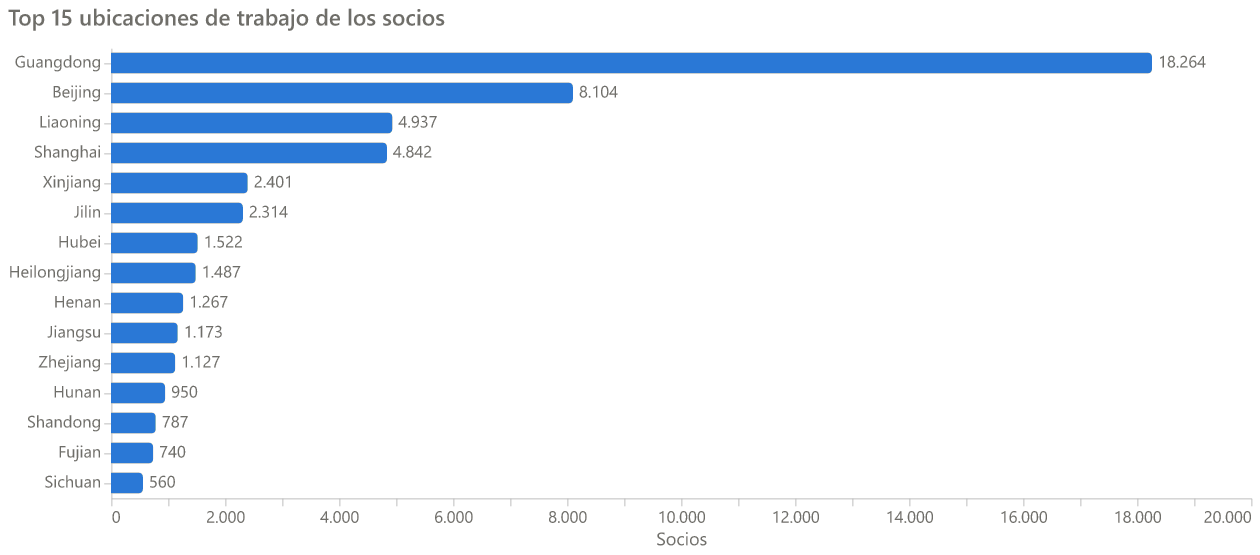

In [12]:
ec.top_locations_chart(df)

El 91,6 % de los socios trabaja en China; Guangdong concentra el 31,7 % y las tres primeras
provincias, el 54,4 %. Es coherente con una aerolínea con *hub* en el sur de China.

## 10. Evolución de las altas

alt.LayerChart(...)
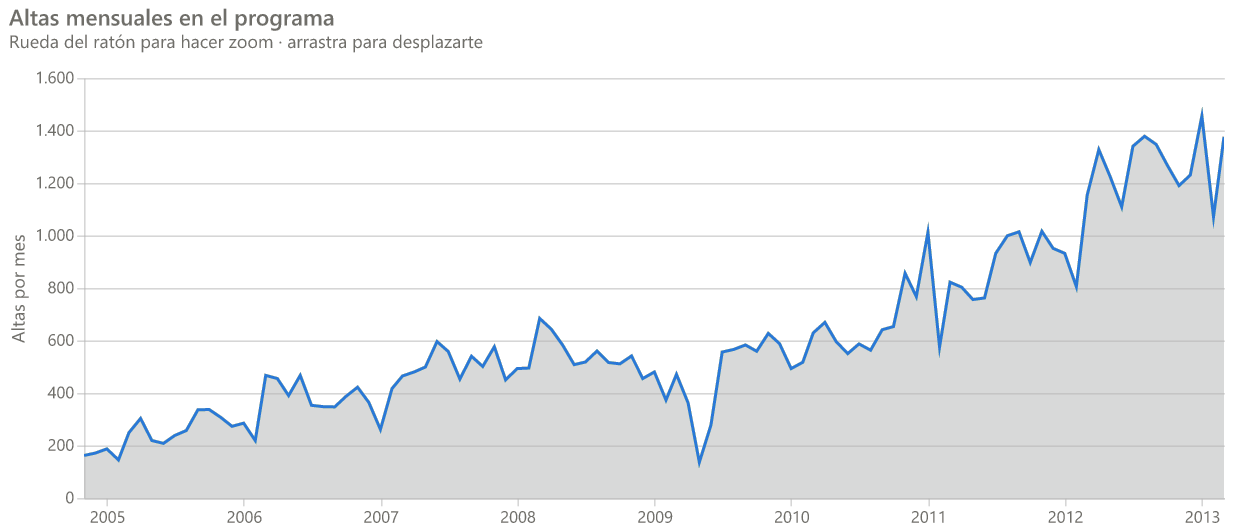

In [13]:
ec.enrollment_chart(df)

Las altas crecen hasta un máximo en 2012, con una caída abrupta en mayo de 2009 (coincide con el
brote de gripe A H1N1). La última alta es del 31/03/2013: todos los socios llevan al menos un
año en el programa.

## 11. Tendencia de ingresos: año 1 vs año 2

Primero, ¿cuál es el año reciente? Si `SUM_YR_2` lo es, los socios sin ingresos en el año 2
deberían llevar más de un año sin volar.

In [14]:
no_yr2 = df["SUM_YR_2"] == 0
inactive = (df.loc[no_yr2, "LAST_TO_END"] > 365).mean()
print(f"Socios con SUM_YR_2 = 0: {no_yr2.mean():.1%}")
print(f"…de ellos, con más de 365 días sin volar: {inactive:.1%}")
naive_trend = (df["SUM_YR_2"] - df["SUM_YR_1"]) / (df["SUM_YR_1"] + 1)
print(f"Fórmula (Y2 − Y1) / (Y1 + 1): máximo = {naive_trend.max():,.0f}  ← explota con Y1 = 0")

Socios con SUM_YR_2 = 0: 17.7%
…de ellos, con más de 365 días sin volar: 93.0%
Fórmula (Y2 − Y1) / (Y1 + 1): máximo = 119,684  ← explota con Y1 = 0


alt.LayerChart(...)
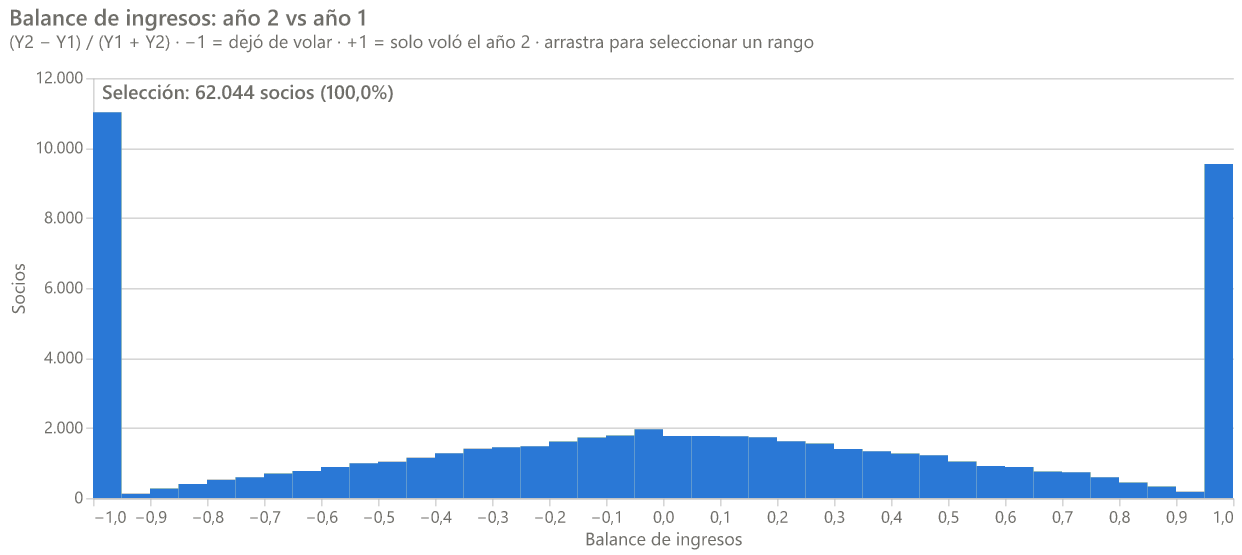

In [15]:
ec.revenue_trend_chart(df)

**Qué vemos.** Hay dos picos en los extremos: un 17,7 % de socios sin ingresos en el año
reciente (balance −1) y un 15,3 % que solo ingresó en ese año (+1).

**Qué implica.** El balance −1 es una señal directa de abandono. Se usará la versión acotada
`(Y2 − Y1) / (Y1 + Y2)` en lugar de `(Y2 − Y1) / (Y1 + 1)`, que explota con `SUM_YR_1 = 0`.

## 12. Conclusiones del EDA

1. **F y M necesitan transformación** (asimetría > 3); Yeo-Johnson normaliza las cinco métricas.
2. **F y M son redundantes** (ρ ≈ 0,9); C aporta una dimensión independiente de sensibilidad al
   precio.
3. **El nivel del programa solo identifica a la élite** (8 % de socios, 30 % del ingreso): el
   valor del clustering está en diferenciar al resto.
4. **Hay una señal clara de abandono**: 17,7 % de socios sin ingresos en el año reciente.
5. `avg_discount` ≈ precio pagado / tarifa completa (confirmado).

Siguiente paso: construcción de las features LRFMC (notebook 03, Fase 4).